In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.colors import LinearSegmentedColormap
import torch
from pathlib import Path
from datetime import datetime
from sklearn.cross_decomposition import PLSRegression
from matplotlib.ticker import FormatStrFormatter

import sys
sys.path.append("../../tools")
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(eva)
#importlib.reload(prep)
#importlib.reload(func)


In [3]:
load_dir1 = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r9")
load_dir2 = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r1")
load_dir3 = Path(f"../../saved_models/num_stable_states_15fold/sp3to20_NS_transpt3_r7")
load_dir4 = Path(f"../../saved_models/fluctuation_15fold_v2/sp3to20_Fl_transpt3_r1")
load_dir5 = Path(f"../../saved_models/swi_species_15fold/sp3to20_SS_transpt3_r13")
emodel = func.load_saved_model_MD(load_dir1, device)
dmodel = func.load_saved_model_MD(load_dir2, device)
nmodel = func.load_saved_model_NS(load_dir3, device)
fmodel = func.load_saved_model_MD(load_dir4, device)
smodel = func.load_saved_model_SS(load_dir5, device)
epredictor = func.Predictor(emodel)
dpredictor = func.Predictor(dmodel)
npredictor = func.Predictor(nmodel)
fpredictor = func.Predictor(fmodel)
spredictor = func.Predictor(smodel)


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [ ]:
#df = pd.read_csv(f"../Fig4/gamma5.csv")
df = pd.read_csv(f"../Fig4/random2.csv")
df = df.dropna()
df["relative_H"] = df["relative_H"].clip(lower=0, upper=1)
df["relative_D"] = df["relative_D"].clip(lower=0, upper=1)

X = df[["richness", "density", "pos_inall", "gamma_neg_mean", "gamma_pos_mean"]].values
steady_num = df["states_number"].values
relative_H = df["relative_H"].values
relative_D = df["relative_D"].values

X_scaled = StandardScaler().fit_transform(X)


In [ ]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis label (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick label (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})

ncmap = LinearSegmentedColormap.from_list("custom_cmap", ["#FFD451", "#F7BC82", "#FF9131","#BA472A"])


**PLS**

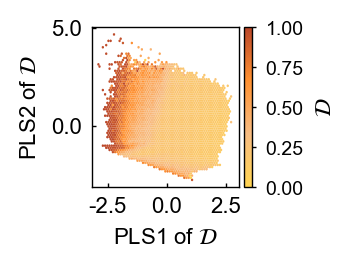

In [50]:
def PLS_draw(emer_pro, cmap, emer_type):

    pls = PLSRegression(n_components=2)
    pls.fit(X_scaled, emer_pro)

    X_pls = pls.transform(X_scaled)
    fig, ax = plt.subplots(figsize=(1,1), dpi=200)

    hb = ax.hexbin(
        X_pls[:, 0],
        X_pls[:, 1],
        C=emer_pro,
        gridsize=60,
        cmap=cmap,
        reduce_C_function=np.mean,
        mincnt=1,
        linewidths=0,
        # vmin=0,
        # vmax=0.2,
        rasterized=True,
    )

    if emer_type == "steady_num":
        clabel = r"$N$"
        pdf_name = "N"
    elif emer_type == "relative_H":
        clabel = r"$\mathcal{H}$"
        pdf_name = "H"
    elif emer_type == "relative_D":
        clabel = r"$\mathcal{D}$"
        pdf_name = "D"

    cbar = plt.colorbar(hb, pad=0.03, fraction=0.05)
    cbar.set_label(clabel, fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    #cbar.set_ticks([1, 5, 9])

    # x_min = X_pls[:, 0].min()
    # x_max = X_pls[:, 0].max()
    # ax.set_xlim(x_min-0.5, x_max+0.5)
    # ax.set_xticks([x_min, x_max])

    ax.set_xlabel(f"PLS1 of {clabel}")
    ax.set_ylabel(f"PLS2 of {clabel}")

    ax.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    #cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

    ax.tick_params(direction='in')
    plt.subplots_adjust(
        left=0.18,
        right=0.98,
        bottom=0.18,
        top=0.98
    )
    plt.savefig(
        f"B_PLS_{pdf_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
        dpi=1000,
        bbox_inches='tight',
        transparent=True
    )

    plt.show()

#PLS_draw(steady_num, ncmap, "steady_num")
#PLS_draw(relative_H, ncmap, "relative_H")
PLS_draw(relative_D, ncmap, "relative_D")


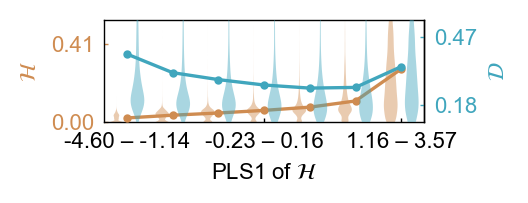

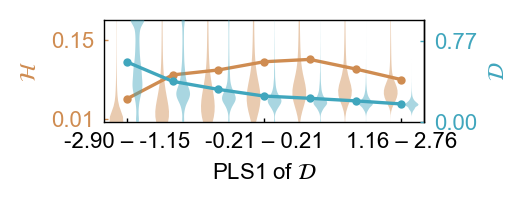

In [ ]:
def PLS_curve_violin(emer_pro1, emer_pro2, fit_type="relative_H"):

    emer_dict = {"relative_H": np.asarray(emer_pro1), "relative_D": np.asarray(emer_pro2)}
    colors = {"relative_H": "#cf8c51", "relative_D": "#40a6bd"}
    labels = {"relative_H": r"$\mathcal{H}$", "relative_D": r"$\mathcal{D}$"}
    pdf_names = {"relative_H": "H", "relative_D": "D"}

    if fit_type not in emer_dict:
        raise ValueError(
            f"Unknown fit_type: {fit_type}. "
            f"Choose from {list(emer_dict.keys())}."
        )

    # ============================================================
    # 1. Fit PLS and sort samples
    # ============================================================

    pls = PLSRegression(n_components=2)
    pls.fit(X_scaled, emer_dict[fit_type])
    X_pls = pls.transform(X_scaled)

    idx = np.argsort(X_pls[:, 0])
    pls1_sorted = X_pls[idx, 0]
    H_sorted = emer_dict["relative_H"][idx]
    D_sorted = emer_dict["relative_D"][idx]

    # ============================================================
    # 2. Create figure
    # ============================================================

    fig, ax_H = plt.subplots(figsize=(2, 0.7), dpi=200)
    ax_D = ax_H.twinx()

    # ============================================================
    # 3. Equal-sample bins after sorting by PLS1
    # ============================================================

    num_violin_bins = 7

    # Equal-sample bins after sorting by PLS1
    x_bins = np.array_split(pls1_sorted, num_violin_bins)
    H_bins = np.array_split(H_sorted, num_violin_bins)
    D_bins = np.array_split(D_sorted, num_violin_bins)

    bin_ranges = np.array([
        [x.min(), x.max()]
        for x in x_bins
    ])

    # Plot positions use equal bin centers
    bin_centers = np.arange(num_violin_bins, dtype=float)

    violin_width = 0.3
    offset = 0.23

    # ============================================================
    # 4. Plot H and D violins
    # ============================================================

    # H violin
    parts_H = ax_H.violinplot(
        H_bins,
        positions=bin_centers - offset,
        widths=violin_width,
        showmeans=False,
        showmedians=False,
        showextrema=False,
        bw_method="scott"
    )

    for body in parts_H["bodies"]:
        body.set_facecolor(colors["relative_H"])
        body.set_edgecolor("none")
        body.set_alpha(0.45)
        body.set_rasterized(True)

    # D violin
    parts_D = ax_D.violinplot(
        D_bins,
        positions=bin_centers + offset,
        widths=violin_width,
        showmeans=False,
        showmedians=False,
        showextrema=False,
        bw_method="scott"
    )

    for body in parts_D["bodies"]:
        body.set_facecolor(colors["relative_D"])
        body.set_edgecolor("none")
        body.set_alpha(0.45)
        body.set_rasterized(True)

    # ============================================================
    # 5. Calculate means and connect them with lines
    # ============================================================

    H_curve_mean = np.array([np.mean(y) for y in H_bins])
    D_curve_mean = np.array([np.mean(y) for y in D_bins])

    ax_H.plot(
        bin_centers, H_curve_mean,
        color=colors["relative_H"],
        linewidth=1.2,
        marker="o",
        markersize=2,
        zorder=5
    )

    ax_D.plot(
        bin_centers, D_curve_mean,
        color=colors["relative_D"],
        linewidth=1.2,
        marker="o",
        markersize=2,
        zorder=5
    )

    # ============================================================
    # 6. Y-axis ranges based on curve minima and maxima
    # ============================================================

    H_min, H_max = H_curve_mean.min(), H_curve_mean.max()
    D_min, D_max = D_curve_mean.min(), D_curve_mean.max()

    H_margin = 1 * (H_max - H_min)
    D_margin = 1 * (D_max - D_min)

    ax_H.set_ylim(max(H_min - H_margin, 0), H_max + H_margin)
    ax_D.set_ylim(max(D_min - D_margin, 0), D_max + D_margin)

    ax_H.set_yticks([max(H_min - H_margin/2, 0), H_max + H_margin/2])
    ax_D.set_yticks([max(D_min - D_margin/2, 0), D_max + D_margin/2])

    # ============================================================
    # 7. X-axis: show only the first and last bin ranges
    # ============================================================

    # Show only the first, middle, and last bin ranges
    tick_positions = [
        bin_centers[0],
        bin_centers[num_violin_bins // 2],
        bin_centers[-1]
    ]

    tick_labels = [
        f"{bin_ranges[0, 0]:.2f} – {bin_ranges[0, 1]:.2f}",
        f"{bin_ranges[num_violin_bins // 2, 0]:.2f} – {bin_ranges[num_violin_bins // 2, 1]:.2f}",
        f"{bin_ranges[-1, 0]:.2f} – {bin_ranges[-1, 1]:.2f}"
    ]

    ax_H.set_xticks(tick_positions)
    ax_H.set_xticklabels(tick_labels)

    # ============================================================
    # 8. Axis labels and tick formatting
    # ============================================================

    ax_H.set_ylabel(labels["relative_H"], color=colors["relative_H"])
    ax_D.set_ylabel(labels["relative_D"], color=colors["relative_D"])

    ax_H.set_xlabel(f"PLS1 of {labels[fit_type]}")

    ax_H.tick_params(axis="y", colors=colors["relative_H"], direction="in")
    ax_D.tick_params(axis="y", colors=colors["relative_D"], direction="in")
    ax_H.tick_params(axis="x", colors="black", direction="in")

    ax_H.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax_D.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

    # Keep all bins visible
    ax_H.set_xlim(-0.5, len(bin_centers) - 0.5)

    # ============================================================
    # 9. Four black borders
    # ============================================================

    for spine in ["left", "bottom", "top"]:
        ax_H.spines[spine].set_visible(True)
        ax_H.spines[spine].set_color("black")

    ax_D.spines["right"].set_visible(True)
    ax_D.spines["right"].set_color("black")

    ax_D.spines["left"].set_visible(False)
    ax_D.spines["top"].set_visible(False)
    ax_D.spines["bottom"].set_visible(False)

    # ============================================================
    # 10. Layout and display
    # ============================================================

    plt.subplots_adjust(
        left=0.18,
        right=0.98,
        bottom=0.25,
        top=0.98
    )

    # Optional PDF export
    pdf_name = pdf_names[fit_type]
    plt.savefig(
        f"B_PLS1_violin_{pdf_name}_{datetime.now():%Y%m%d_%H%M%S}.pdf",
        dpi=1000,
        bbox_inches="tight",
        transparent=True
    )

    plt.show()

#PLS_curve(steady_num, relative_H, relative_D, fit_type="steady_num")
# PLS_curve2(relative_H, relative_D, fit_type="relative_H")
# PLS_curve2(relative_H, relative_D, fit_type="relative_D")

# PLS_violin(relative_H, relative_D, fit_type="relative_H")
# PLS_violin(relative_H, relative_D, fit_type="relative_D")

PLS_curve_violin(relative_H, relative_D, fit_type="relative_H")
PLS_curve_violin(relative_H, relative_D, fit_type="relative_D")


**richness, density, pos_inall, gamma_neg_mean, gamma_pos_mean**

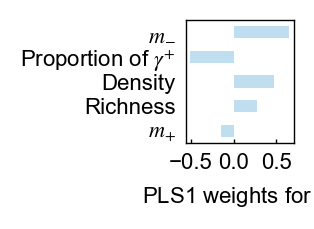

In [ ]:
pls = PLSRegression(n_components=2)
pls.fit(X_scaled, steady_num)

# sort weights by absolute value
weights = (
    pd.Series(pls.x_weights_[:, 0], 
              #index=("Richness", "Density", r"Proportion of $\gamma^{+}$", r"$m_{-}$", r"$m_{+}$", r"mean $|\gamma|$")
              index=("Richness", "Density", r"Proportion of $\gamma^{+}$", r"$m_{-}$", r"$m_{+}$")
            )
    .sort_values(key=np.abs, ascending=False)
)

plt.figure(figsize=(0.7, 0.8), dpi=200)
weights.plot.barh(color="#BFDEEF")

#plt.xlabel(r"PLS1 weights for $N$")
#plt.xlabel(r"PLS1 weights for $\mathcal{D}$")
plt.xlabel(r"PLS1 weights for $\mathcal{H}$")

plt.gca().invert_yaxis()  
plt.tick_params(direction='in')

ax = plt.gca()
ax.tick_params(axis='y', which='both', length=0) 

plt.savefig(
    f"B_PLS1_weight_random2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.svg",
    dpi=1000,
    bbox_inches='tight',
    #pad_inches=3,
    transparent=True
)
